# Covariate-adjusted perturbation effects on a genome-scale CD4+ T-cell screen

A perturbation's cells and the control cells rarely come from the same mix of donors, 10x lanes and
sequencing depths. A plain target-versus-control comparison reads those differences as perturbation
effects. `cx.tl.residual_effects` implements the estimator of Feng et al. (2025, *Cell Genomics*):

1. normalise every cell to `log1p` counts per 10,000;
2. regress each gene on the covariates (donor, lane, log total counts, mitochondrial share, ...)
   **over the control cells only**, by ordinary least squares;
3. a perturbation's effect is the mean, over its cells, of observed minus predicted expression,
   tested against the control fit's residual spread.

crispyx does this in **one streaming pass** over the raw counts: it collects per-perturbation sums and
the controls' cross-products, then solves a small least-squares problem. No per-cell residual is
stored and the matrix is never loaded.

**Data.** The resting-state CD4+ T cells of three donors (D1–D3) from the genome-scale CRISPRi
Perturb-seq of Zhu, Dann, Marson *et al.* (bioRxiv 2025): 5.6 million cells, 18,130 genes, 21.5 billion
non-zero counts, 12,500 knocked-down genes. The authors' own estimates (DESeq2 on donor x guide
pseudo-bulk) are published alongside, so the tutorial ends by comparing the two.

**Resources.** Executed on a Linux server restricted to 32 cores (`taskset`); the table at the end
lists the wall time and peak memory of each step, against a budget of 3 hours and 256 GB.

In [1]:
import os
import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
# Progress bars off, so the saved notebook keeps only crispyx's summary lines.
os.environ.setdefault('TQDM_DISABLE', '1')
warnings.filterwarnings('ignore', message='IProgress not found')
import crispyx as cx

DATA_DIR = ROOT / 'data' / 'gwcd4i'
OUTPUT_DIR = Path('tutorial_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DONORS = ['D1', 'D2', 'D3']

cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
print(f'crispyx {cx.__version__}, {cores} cores')

steps = []


@contextmanager
def measured(step):
    """Record a step's wall time and this process's peak memory while it runs."""
    with cx.Profiler(timing=True, sampling=True, memory_method='rss', sample_interval=0.5) as profiler:
        yield
    stats = profiler.get_stats()
    minutes = stats['timing']['total_seconds'] / 60
    peak_gb = stats['memory']['peak_mb'] / 1024
    steps.append({'step': step, 'wall time (min)': round(minutes, 1), 'peak RSS (GB)': round(peak_gb, 1)})
    print(f'{step}: {minutes:.1f} min, peak RSS {peak_gb:.1f} GB')


@contextmanager
def warnings_as_messages():
    # print crispyx's warnings by message only: the default banner names the source file
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        warnings.simplefilter('ignore', DeprecationWarning)
        yield
    for message in dict.fromkeys(f'{w.category.__name__}: {w.message}' for w in caught):
        print(message)

crispyx 0.1.9, 32 cores


## 1. Get the data

The files are public (MIT licence) in the S3 bucket `genome-scale-tcell-perturb-seq`; no account is
needed. Each donor's resting-state file holds every captured cell, 138–143 GB of raw counts. Run once,
from the repository root (this cell is not executed here):

```bash
mkdir -p data/gwcd4i && cd data/gwcd4i
BUCKET=https://genome-scale-tcell-perturb-seq.s3.amazonaws.com/marson2025_data
for donor in D1 D2 D3; do curl -O "$BUCKET/${donor}_Rest.assigned_guide.h5ad"; done
curl -O "$BUCKET/GWCD4i.DE_stats.h5ad"   # the authors' DE results, 16.8 GB
```

## 2. Keep the guide-resolved cells, on disk

Each file also contains cells without a detected guide, cells with several guides and cells flagged as
low quality. `cx.write_filtered_subset` streams one file to a new one, keeping the rows of a boolean
mask; row chunks without a kept cell are not read. The mask comes from `obs` alone, read with
`cx.load_obs` without touching the matrix.

In [2]:
filtered = {}
with measured('keep guide-resolved cells (3 files)'):
    for donor in DONORS:
        source = DATA_DIR / f'{donor}_Rest.assigned_guide.h5ad'
        obs = cx.load_obs(source)
        keep = (
            obs['guide_type'].eq('non-targeting')
            | (obs['guide_type'].eq('targeting') & obs['perturbed_gene_name'].notna())
        ) & ~obs['low_quality'].astype(bool)
        filtered[donor] = OUTPUT_DIR / f'{donor}.h5ad'
        with warnings_as_messages():
            cx.write_filtered_subset(
                source,
                cell_mask=keep.to_numpy(),
                gene_mask=np.ones(len(cx.load_var(source)), dtype=bool),
                output_path=filtered[donor],
            )
        print(f'{donor}: kept {keep.sum():,} of {len(obs):,} cells')

D1: kept 1,752,037 of 3,074,496 cells


D2: kept 1,983,457 of 2,940,194 cells


D3: kept 1,901,710 of 2,778,524 cells
keep guide-resolved cells (3 files): 41.5 min, peak RSS 2.7 GB


## 3. Concatenate the donors, on disk

`cx.pp.concat_h5ad` writes the three files into one CSR matrix, streaming each file in row chunks.
`label='donor'` records each cell's source file (its stem) in `obs['donor']`. The barcodes carry a
sample suffix, so no cell occurs in two files; `shared_cells='error'` makes the call check that
instead of assuming it.

The files do not list their genes in the same order: D3's columns are a permutation of D1's. Genes are
matched by name, so each column of the output means the same gene for every cell. Stacking the
matrices as they are would silently relabel all of D3's genes.

In [3]:
merged_path = OUTPUT_DIR / 'CD4T_Rest_D1-D3.h5ad'
gene_order = {donor: list(cx.load_var(filtered[donor]).index) for donor in DONORS}
print('same gene order as D1:', {donor: gene_order[donor] == gene_order['D1'] for donor in DONORS})
with measured('concatenate the donors'), warnings_as_messages():
    merged = cx.pp.concat_h5ad(
        [filtered[donor] for donor in DONORS],
        output_path=merged_path, label='donor', shared_cells='error',
    )
merged

same gene order as D1: {'D1': True, 'D2': True, 'D3': False}


[cx] pp.concat_h5ad: Done  5637204 cells × 18130 genes
[cx] pp.concat_h5ad: Saving → tutorial_outputs/CD4T_Rest_D1-D3.h5ad
concatenate the donors: 15.6 min, peak RSS 4.0 GB


AnnData(path=tutorial_outputs/CD4T_Rest_D1-D3.h5ad, mode='r')

## 4. Labels and covariates

The perturbation label is the targeted gene, or `non-targeting` for the controls. It is passed as a
`pd.Series` indexed by cell, so nothing is written back into the file.

Lanes are shared between donors: the first 10x run (lanes `CD4i_R1L..`) holds donors D1 and D2, the
second (`CD4i_R2L..`) donors D3 and D4. With D4 left out, the second run's lanes contain only D3, so
the donor and lane columns overlap; `residual_effects` notes that the design is rank deficient,
which leaves the fitted values and the effects unchanged.

In [4]:
obs = cx.load_obs(merged_path)
labels = (
    obs['perturbed_gene_name'].astype(object)
    .where(obs['guide_type'].ne('non-targeting'), 'non-targeting')
    .rename('perturbation')
)
print(f'{len(obs):,} cells, {labels.nunique() - 1:,} targeted genes, '
      f"{(labels == 'non-targeting').sum():,} control cells")
pd.crosstab(obs['lane_id'].str[:7].rename('10x run'), obs['donor'])

5,637,204 cells, 12,511 targeted genes, 237,353 control cells


donor,D1,D2,D3
10x run,,,
CD4i_R1,1752037,1983457,0
CD4i_R2,0,0,1901710


## 5. Effects

Two calls: the covariate-adjusted estimate, and the same estimator with no covariates (each
perturbation's mean minus the controls' mean), to see what the adjustment changes. Raw-count genes
are indexed by Ensembl ID here, so `gene_name_column` names the column with gene symbols;
`mito_fraction` uses the genes whose symbol starts with `MT-`.

In [5]:
covariates = ['donor', 'lane_id', 'log_total_counts', 'mito_fraction']
with measured('residual_effects, adjusted'):
    adjusted = cx.tl.residual_effects(
        merged_path, labels, 'non-targeting',
        covariates=covariates, gene_name_column='gene_name',
        output_path=OUTPUT_DIR / 'cd4t_residual_effects.h5ad',
    )
adjusted

[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest_D1-D3.h5ad


[cx] residual_effects: 506 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'DNA2', 'PNO1', 'AMMECR1L', 'ABCF1', 'SMC3', 'PI4KA', 'C19orf25', 'GOLT1B', 'GUCA2B']


[cx] residual_effects: 12,005 perturbations, 237,353 control cells, design: 51 columns


[cx] residual_effects: the design has rank 50 < 51 columns (collinear covariates); fitted values and effects are still unique.


[cx] residual_effects: estimated disk usage: 7.7 GB (30.1 TB free)


[cx] residual_effects: 12,005 perturbations x 18,130 genes (7,975 tested), model null
[cx] residual_effects: Saving → tutorial_outputs/cd4t_residual_effects.h5ad
residual_effects, adjusted: 2.8 min, peak RSS 10.8 GB


AnnData(path=tutorial_outputs/cd4t_residual_effects.h5ad, mode='r')

In [6]:
with measured('residual_effects, no covariates'):
    unadjusted = cx.tl.residual_effects(
        merged_path, labels, 'non-targeting',
        covariates=[], gene_name_column='gene_name',
        output_path=OUTPUT_DIR / 'cd4t_unadjusted_effects.h5ad',
    )

[cx] residual_effects: Reading tutorial_outputs/CD4T_Rest_D1-D3.h5ad


[cx] residual_effects: 506 perturbation(s) have fewer than 10 cells and are left out: ['NOL10', 'DNA2', 'PNO1', 'AMMECR1L', 'ABCF1', 'SMC3', 'PI4KA', 'C19orf25', 'GOLT1B', 'GUCA2B']
[cx] residual_effects: 12,005 perturbations, 237,353 control cells, design: 1 columns


[cx] residual_effects: estimated disk usage: 7.7 GB (30.1 TB free)


[cx] residual_effects: 12,005 perturbations x 18,130 genes (7,975 tested), model null
[cx] residual_effects: Saving → tutorial_outputs/cd4t_unadjusted_effects.h5ad
residual_effects, no covariates: 2.5 min, peak RSS 15.6 GB


`X` holds the effect: a difference of mean `log1p(CP10k)` values (natural log), **not** a log2 fold
change. `z_score`, `pvalue` and `pvalue_adj` (Benjamini–Hochberg within each perturbation) are
layers; `var` holds the control mean, the two spreads a z-score can be divided by, and which genes
were tested (control mean above 0.1, as in Feng et al.).

In [7]:
adjusted.backed.var.head()

,control_mean,residual_sd,robust_sd,tested
gene_name,,,,
TSPAN6,0.000060,0.006828,0.000523,False
TNMD,0.000003,0.001448,0.000057,False
DPM1,0.801106,0.592264,0.668056,True
SCYL3,0.264869,0.432566,0.453736,True
C1orf112,0.385325,0.495380,0.712384,True


The default `null='model'` divides by the control fit's residual standard deviation and treats cells
as independent. Cells sharing a guide or a donor are not, so the paper's own test is somewhat
anti-conservative. `null='robust'` divides by 1.4826 x the median absolute deviation of
`effect * sqrt(n)` across perturbations instead; it suits genome-wide screens, where most
perturbations leave a given gene unchanged. Both spreads are in `var`, so the robust z-score needs no
second pass:

In [8]:
def read_result(result):
    with h5py.File(result.path, 'r') as handle:
        effect, z = handle['X'][:], handle['layers/z_score'][:]
    backed = result.backed
    return (pd.Index(backed.obs_names), pd.Index(backed.var_names), effect, z,
            backed.obs['n_cells'].to_numpy(), backed.var)


targets, genes, effect, z_model, n_cells, gene_info = read_result(adjusted)
robust_sd = gene_info['robust_sd'].to_numpy()
usable = gene_info['tested'].to_numpy() & (robust_sd > 0)
z_robust = np.full_like(effect, np.nan)
z_robust[:, usable] = effect[:, usable] * np.sqrt(n_cells)[:, None] / robust_sd[usable]
*_, effect_unadj, z_unadj, _, _ = read_result(unadjusted)
print(f'{len(targets):,} perturbations x {len(genes):,} genes, {int(gene_info["tested"].sum()):,} tested; '
      f'robust / model spread at the median gene: {np.nanmedian(gene_info["robust_sd"] / gene_info["residual_sd"]):.2f}')

12,005 perturbations x 18,130 genes, 7,975 tested; robust / model spread at the median gene: 1.06


## 6. Compare with the authors' estimates

`GWCD4i.DE_stats.h5ad` holds the authors' DESeq2 results for every target and culture condition
(guide x donor pseudo-bulk sums, all four donors). Its layers are dense, so only the rows of the
resting-state targets we share are read. Targets and genes are matched by symbol.

The two estimates are on different scales — theirs a DESeq2 log2 fold change of pseudo-bulk sums,
ours a difference of mean `log1p(CP10k)` — so the comparison is of z-scores and directions per
target, not of values.

In [9]:
paper_path = DATA_DIR / 'GWCD4i.DE_stats.h5ad'
paper_obs = cx.load_obs(paper_path)
paper_genes = pd.Index(cx.load_var(paper_path)['gene_name'])
rest = paper_obs[paper_obs['culture_condition'] == 'Rest']
rest = rest[~rest['target_contrast_gene_name'].duplicated(keep=False)]
shared_targets = pd.Index(rest['target_contrast_gene_name']).intersection(targets)
shared_genes = paper_genes.intersection(genes[gene_info['tested'].to_numpy()])

rows = np.sort(paper_obs.index.get_indexer(rest.index[rest['target_contrast_gene_name'].isin(shared_targets)]))
row_targets = pd.Index(paper_obs['target_contrast_gene_name'].to_numpy()[rows])
paper_cols = paper_genes.get_indexer(shared_genes)
with h5py.File(paper_path, 'r') as handle:
    # dense, uncompressed layers: one sequential read each, then the rows we need
    paper = {name: handle['layers'][name][:][rows][:, paper_cols] for name in ('zscore', 'log_fc', 'adj_p_value')}

ours = targets.get_indexer(row_targets)
our_cols = genes.get_indexer(shared_genes)
estimates = {
    'adjusted (model null)': (effect[ours][:, our_cols], z_model[ours][:, our_cols]),
    'adjusted (robust null)': (effect[ours][:, our_cols], z_robust[ours][:, our_cols]),
    'no covariates': (effect_unadj[ours][:, our_cols], z_unadj[ours][:, our_cols]),
}
strong = rest.set_index('target_contrast_gene_name').loc[row_targets, 'n_total_de_genes'].to_numpy() >= 10
print(f'{len(row_targets):,} shared targets ({strong.sum():,} with >= 10 DE genes in the paper), '
      f'{len(shared_genes):,} shared tested genes')

10,969 shared targets (2,491 with >= 10 DE genes in the paper), 7,385 shared tested genes


In [10]:
def per_target_r(a, b):
    # Pearson r of each row of a with the same row of b, over genes finite in both
    ok = np.isfinite(a) & np.isfinite(b)
    n = ok.sum(axis=1, keepdims=True)
    a = np.where(ok, a, 0.0)
    b = np.where(ok, b, 0.0)
    a = np.where(ok, a - a.sum(axis=1, keepdims=True) / n, 0.0)
    b = np.where(ok, b - b.sum(axis=1, keepdims=True) / n, 0.0)
    return (a * b).sum(axis=1) / np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))


hits = paper['adj_p_value'] < 0.1
non_hits = (paper['adj_p_value'] >= 0.1) & np.isfinite(paper['zscore'])
per_target = {}
rows_table = []
for name, (est_effect, est_z) in estimates.items():
    r = per_target_r(est_z, paper['zscore'])
    per_target[name] = r
    rows_table.append({
        'estimate': name,
        'median r(z), all targets': np.nanmedian(r),
        'median r(z), targets with >= 10 paper DE genes': np.nanmedian(r[strong]),
        "sign agreement on the paper's hits": np.mean(np.sign(est_z[hits]) == np.sign(paper['zscore'][hits])),
        "|z| > 3 among the paper's non-hits": np.mean(np.abs(est_z[non_hits & np.isfinite(est_z)]) > 3),
    })
pd.DataFrame(rows_table).set_index('estimate').round(3)

,"median r(z), all targets","median r(z), targets with >= 10 paper DE genes",sign agreement on the paper's hits,|z| > 3 among the paper's non-hits
estimate,,,,
adjusted (model null),0.671,0.700,0.959,0.041
adjusted (robust null),0.707,0.728,0.959,0.010
no covariates,0.635,0.692,0.969,0.067


Under a correct null, 0.27% of genes reach |z| > 3. The paper's non-hits are not all true nulls
(four-donor pseudo-bulk DESeq2 is conservative), so the last column is an upper bound on
miscalibration rather than a measurement of it.

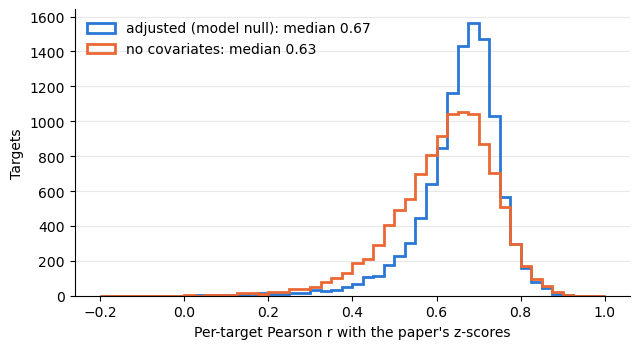

In [11]:
ADJUSTED, UNADJUSTED = '#2a78d6', '#eb6834'
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.linspace(-0.2, 1.0, 49)
for name, color in (('adjusted (model null)', ADJUSTED), ('no covariates', UNADJUSTED)):
    ax.hist(per_target[name][np.isfinite(per_target[name])], bins=bins, histtype='step', linewidth=2, color=color,
            label=f'{name}: median {np.nanmedian(per_target[name]):.2f}')
ax.set_xlabel("Per-target Pearson r with the paper's z-scores")
ax.set_ylabel('Targets')
ax.legend(frameon=False, loc='upper left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.grid(axis='y', color='#e8e8e6', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()

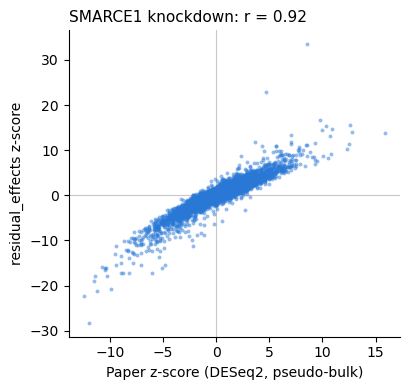

In [12]:
example = row_targets[np.argmax(np.where(strong, np.nan_to_num(per_target['adjusted (model null)'], nan=-1), -np.inf))]
i = row_targets.get_loc(example)
fig, ax = plt.subplots(figsize=(4.2, 4.0))
ax.scatter(paper['zscore'][i], estimates['adjusted (model null)'][1][i], s=8, color=ADJUSTED, alpha=0.5, linewidths=0)
ax.axhline(0, color='#c8c8c4', linewidth=0.8, zorder=0)
ax.axvline(0, color='#c8c8c4', linewidth=0.8, zorder=0)
ax.set_xlabel('Paper z-score (DESeq2, pseudo-bulk)')
ax.set_ylabel('residual_effects z-score')
ax.set_title(f'{example} knockdown: r = {per_target["adjusted (model null)"][i]:.2f}', loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

The knocked-down gene itself should go down. Among targets whose gene is measured and tested:

In [13]:
own = genes.get_indexer(targets)
measured_own = (own >= 0) & gene_info['tested'].to_numpy()[np.maximum(own, 0)]
own_effect = effect[np.flatnonzero(measured_own), own[measured_own]]
print(f'{measured_own.sum():,} targets: own-gene effect negative for {np.mean(own_effect < 0):.1%}, '
      f'median {np.median(own_effect):.2f} (log1p CP10k)')

7,090 targets: own-gene effect negative for 97.8%, median -0.25 (log1p CP10k)


## 7. Resources

Wall time and peak resident memory of this notebook's process for each step. The two effect runs
read a file that had just been written, so much of it was still in the page cache; from a cold disk
the same pass takes about 7.5 minutes on this machine, still a fraction of the filtering and
concatenation, which read and write the full data.

In [14]:
resources = pd.DataFrame(steps).set_index('step')
resources.loc['total'] = [resources['wall time (min)'].sum(), resources['peak RSS (GB)'].max()]
resources

,wall time (min),peak RSS (GB)
step,,
keep guide-resolved cells (3 files),41.5,2.7
concatenate the donors,15.6,4.0
"residual_effects, adjusted",2.8,10.8
"residual_effects, no covariates",2.5,15.6
total,62.4,15.6


**Takeaways**

- Filtering, concatenating and estimating effects for 5.6 million cells all run from disk, within
  the budget in the table above; memory stays far below the size of the data.
- Against the authors' donor-replicated pseudo-bulk analysis, the covariate-adjusted estimates agree
  slightly better per target than the unadjusted ones, and they are better calibrated: among the
  paper's non-hits, |z| > 3 is rarer with the adjusted model null than without covariates, and rarer
  still with the robust null (see the table in section 6).
- Use `null='robust'` (or recompute it from `var['robust_sd']`) on genome-wide screens, where the
  cell-level test is anti-conservative; keep `null='model'` for focused panels, where most
  perturbations are active.